<a href="https://colab.research.google.com/github/2903-adi/23BIT202_CV_Lab_2026-H10-/blob/main/CV_LAB_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import torch

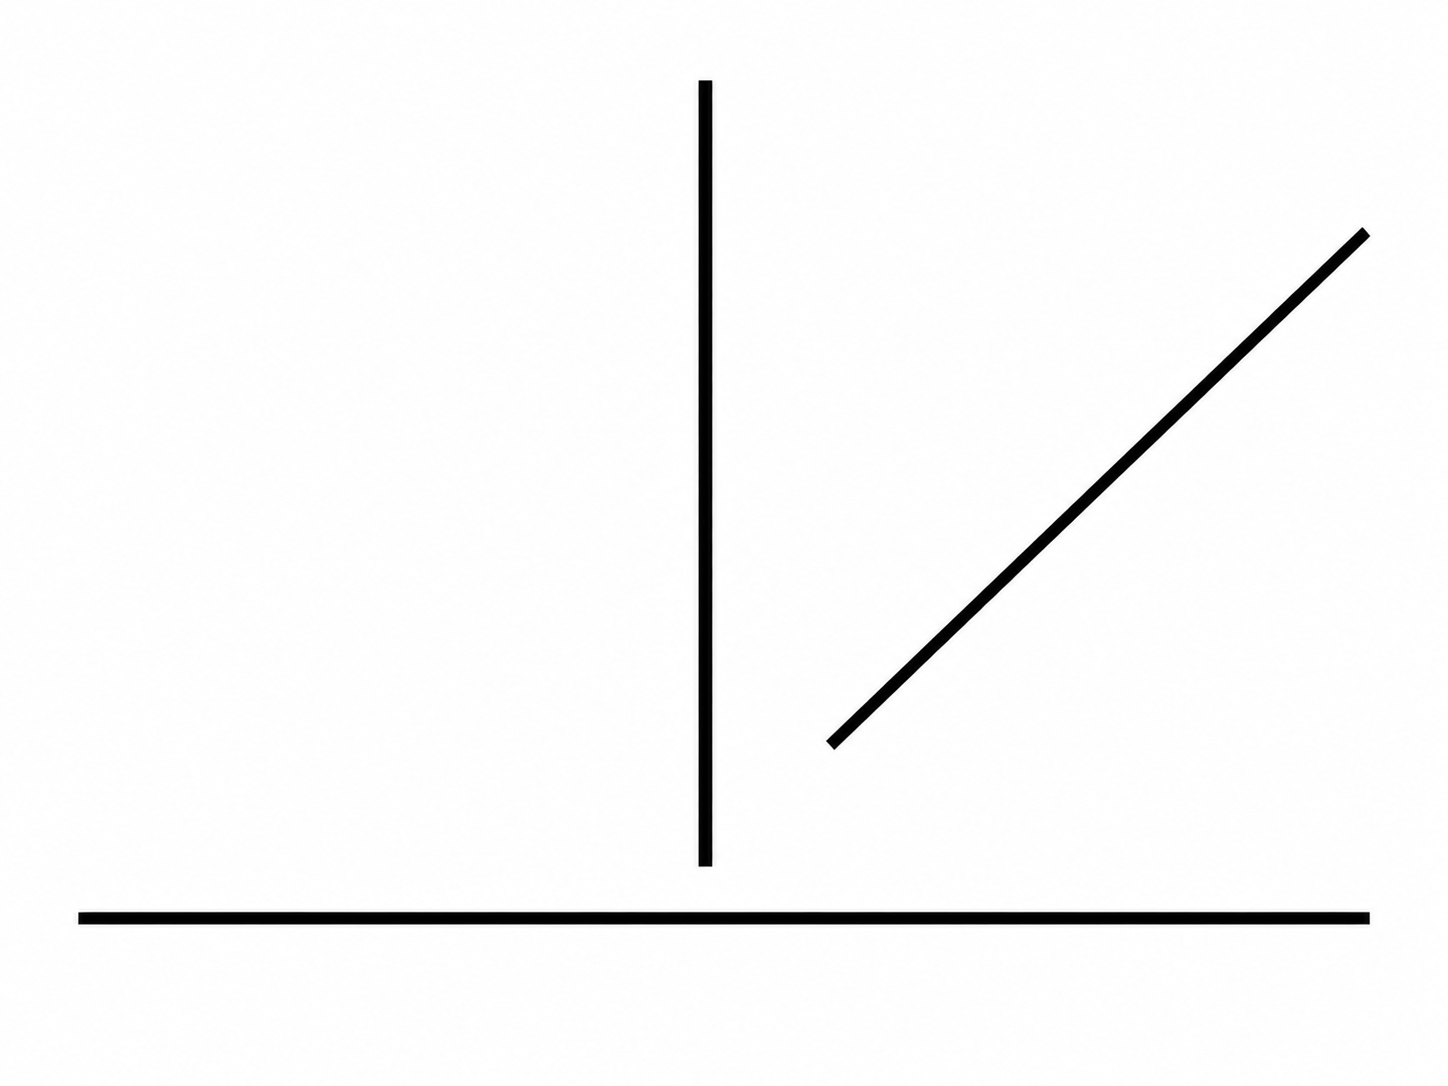

In [ ]:
image = cv2.imread("/content/hough.png" , cv2.IMREAD_GRAYSCALE)
cv2_imshow(image)

Using device: cuda


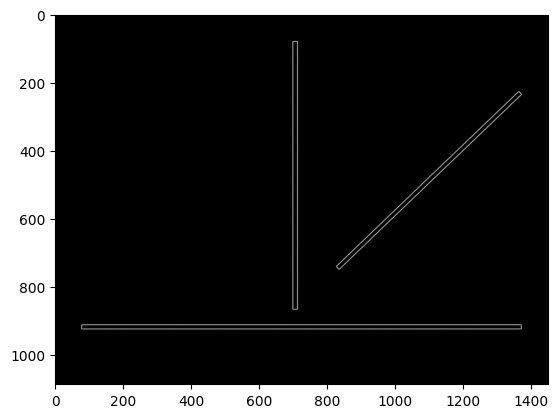

In [ ]:
# Use PyTorch with GPU acceleration for Sobel filtering
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Convert image to Torch tensor and move to GPU
img_tensor = torch.tensor(image, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(0)

# Define Sobel Kernels
sobel_y = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(0)
sobel_x = sobel_y.transpose(-2, -1)

# Apply padding and perform convolution
padded_img = torch.nn.functional.pad(img_tensor, (1, 1, 1, 1), mode='replicate')
detect_x = torch.nn.functional.conv2d(padded_img, sobel_x)[0, 0]
detect_y = torch.nn.functional.conv2d(padded_img, sobel_y)[0, 0]

# Calculate gradient magnitude and move back to CPU for visualization
resultant_tensor = torch.sqrt(detect_x ** 2 + detect_y ** 2)
resultant = resultant_tensor.cpu().numpy()

plt.imshow(resultant, cmap='gray')
plt.show()

In [ ]:
# Accelerate Hough Accumulator using GPU matrix operations
width = resultant.shape[1]
height = resultant.shape[0]

D = int(np.ceil(np.sqrt(width**2 + height**2)))
p_gpu = torch.zeros((2 * D + 1, 180), dtype=torch.int32, device=device)

# Get indices where edge intensity is non-zero
edge_y, edge_x = torch.where(resultant_tensor > 50)  # Using a threshold to filter out noise

# Precompute cos and sin on the GPU
theta = torch.arange(180, dtype=torch.float32, device=device)
theta_rad = torch.deg2rad(theta)
cos_t = torch.cos(theta_rad)
sin_t = torch.sin(theta_rad)

# Compute rho values for all edge pixels in a vectorized manner on GPU
if len(edge_y) > 0:
    # Reshape coordinates for broadcasting: [num_pixels, 1]
    x_coords = edge_x.unsqueeze(1)
    y_coords = edge_y.unsqueeze(1)

    # Calculate rho matrix of shape [num_pixels, 180]
    rho = torch.round(x_coords * cos_t + y_coords * sin_t).to(torch.int32) + D

    # Accumulate votes securely
    theta_indices = torch.arange(180, device=device).unsqueeze(0).expand(rho.shape[0], -1)
    p_gpu.index_put_((rho, theta_indices), torch.ones_like(rho), accumulate=True)

p = p_gpu.cpu().numpy()
print('Hough Accumulator space built successfully on GPU.')

Hough Accumulator space built successfully on GPU.


Detected lines: 872


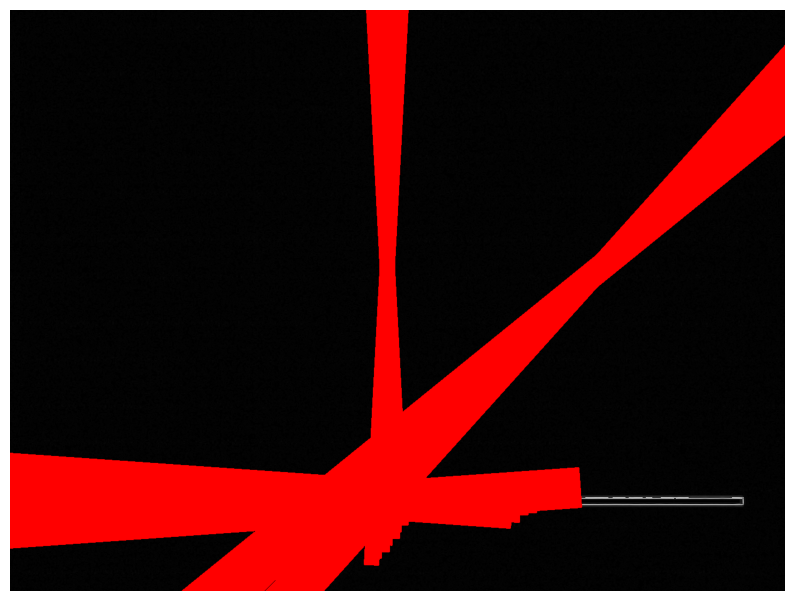

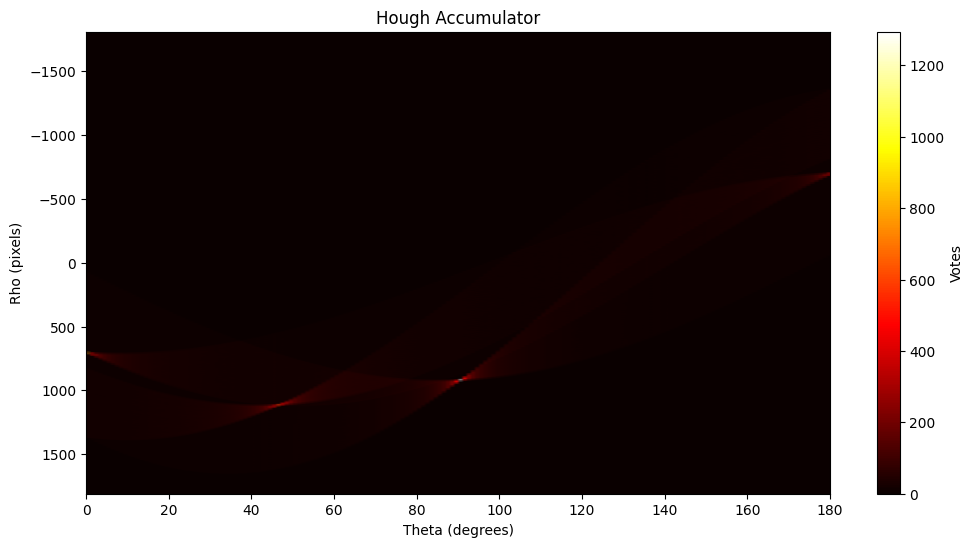

In [ ]:
threshold = 100

# Find matching points using PyTorch on the GPU for faster threshold extraction
rho_idx_gpu, theta_idx_gpu = torch.where(p_gpu >= threshold)

# Convert indices to CPU numpy arrays
rho_idx = rho_idx_gpu.cpu().numpy()
theta_idx = theta_idx_gpu.cpu().numpy()

lines = []
for r, t in zip(rho_idx, theta_idx):
    rho = r - D
    theta = np.deg2rad(t)
    lines.append((rho, theta))

print("Detected lines:", len(lines))

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Build visualization of output lines
output = cv2.cvtColor(
    resultant.astype(np.uint8),
    cv2.COLOR_GRAY2BGR
)

for rho, theta in lines:
    a = np.cos(theta)
    b = np.sin(theta)

    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * a)
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * a)

    cv2.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(
    p,
    cmap="hot",
    aspect="auto",
    extent=[0, 180, D, -D]
)
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Hough Accumulator")
plt.colorbar(label="Votes")
plt.show()

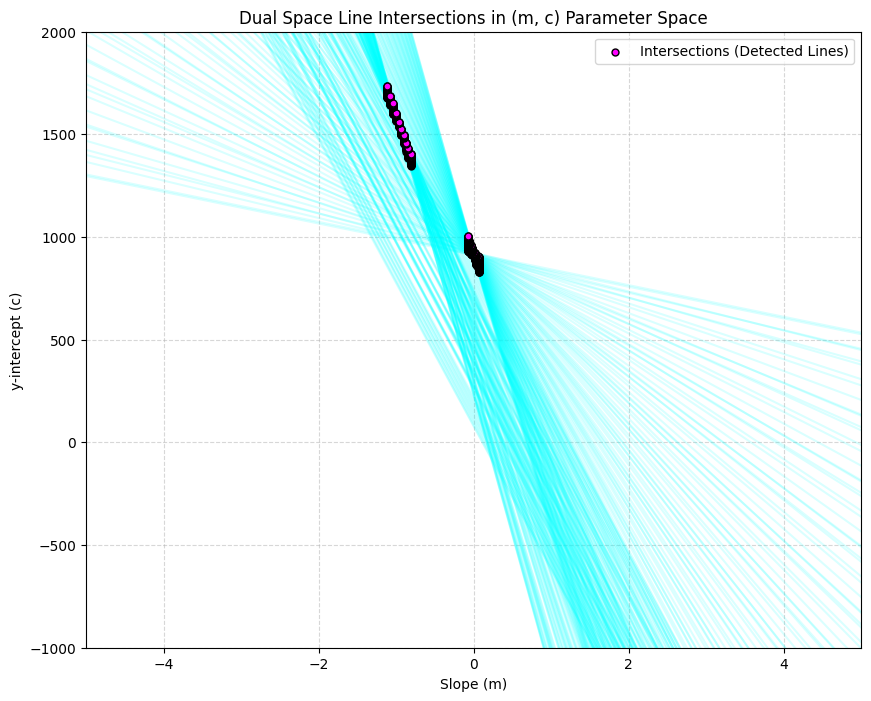

In [ ]:
# Visualize the lines in (m, c) parameter space to show the star-like intersections
plt.figure(figsize=(10, 8))

# Get active edge pixel coordinates from the GPU tensor
edge_y, edge_x = torch.where(resultant_tensor > 50)
# Downsample edge pixels slightly for clean visualization of intersecting lines
step = max(1, len(edge_x) // 300)
edge_x_cpu = edge_x[::step].cpu().numpy()
edge_y_cpu = edge_y[::step].cpu().numpy()

# Plot the line c = -x * m + y for each active pixel
m_range = np.linspace(-5, 5, 500)
for x, y in zip(edge_x_cpu, edge_y_cpu):
    c_vals = -x * m_range + y
    plt.plot(m_range, c_vals, color='cyan', alpha=0.15)

# Also plot the final detected (m, c) points where these lines intersect
detected_m = []
detected_c = []
for rho, theta in lines:
    sin_t = np.sin(theta)
    if np.abs(sin_t) > 0.1:  # Filter out vertical lines to prevent extreme scaling
        m = -np.cos(theta) / sin_t
        c = rho / sin_t
        if -5 <= m <= 5:
            detected_m.append(m)
            detected_c.append(c)

plt.scatter(detected_m, detected_c, color='magenta', zorder=5, s=25, edgecolor='black', label='Intersections (Detected Lines)')
plt.xlim(-5, 5)
plt.ylim(-1000, 2000)
plt.xlabel("Slope (m)")
plt.ylabel("y-intercept (c)")
plt.title("Dual Space Line Intersections in (m, c) Parameter Space")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Analyzing the Intersections of the 3 Lines
Let's check the slopes ($m$) and intercepts ($c$) of the three most dominant lines to see if parallel lines are causing one of the intersections to disappear or exist at infinity.

In [ ]:
# Calculate and print the top 3 dominant unique lines from the accumulator
# Sort the accumulator p_gpu to find the highest peak coordinates
flat_indices = torch.argsort(p_gpu.flatten(), descending=True)
top_rhos = []
top_thetas = []

# Extract unique peaks (avoiding duplicates from the same peak neighborhood)
visited = np.zeros_like(p)
for idx in flat_indices.cpu().numpy():
    r, t = np.unravel_index(idx, p.shape)
    if visited[max(0, r-10):r+10, max(0, t-10):t+10].sum() == 0:
        visited[r, t] = 1
        top_rhos.append(r - D)
        top_thetas.append(np.deg2rad(t))
        if len(top_rhos) == 3:
            break

# Convert to m and c slope-intercept parameters
print("Top 3 Detected Line Parameters:")
for idx, (rho, theta) in enumerate(zip(top_rhos, top_thetas)):
    sin_t = np.sin(theta)
    if np.abs(sin_t) > 1e-6:
        m = -np.cos(theta) / sin_t
        c = rho / sin_t
        print(f"Line {idx+1}: y = {m:.4f}*x + {c:.4f} (Theta: {np.rad2deg(theta):.1f}°, Rho: {rho})")
    else:
        print(f"Line {idx+1}: Vertical line (Theta: {np.rad2deg(theta):.1f}°, Rho: {rho})")

Top 3 Detected Line Parameters:
Line 1: y = -0.0000*x + 911.0000 (Theta: 90.0°, Rho: 911)
Line 2: y = -0.0000*x + 923.0000 (Theta: 90.0°, Rho: 923)
Line 3: Vertical line (Theta: 0.0°, Rho: 697)
